In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [ ]:
# Load the dataset
link = 'https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv'

# Read the dataset into a DataFrame
df= pd.read_csv(link)

# Clean the column names
df.columns=df.columns.str.strip().str.replace(' ', '_').str.replace('[^A-Za-z0-9_]+','',regex=True)

In [ ]:
# Save the DataFrame to a CSV file
df.to_csv('BostonHousing_raw.csv', index=False)

In [ ]:
# Display the first few rows of the DataFrame
df.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [ ]:
# Display the DataFrame information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       506 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    int64  
 10  ptratio  506 non-null    float64
 11  b        506 non-null    float64
 12  lstat    506 non-null    float64
 13  medv     506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB


In [ ]:
# Display the summary statistics of the DataFrame
df.describe()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


In [ ]:
# Display the number of missing values in each column
df.isnull().sum()

crim       0
zn         0
indus      0
chas       0
nox        0
rm         0
age        0
dis        0
rad        0
tax        0
ptratio    0
b          0
lstat      0
medv       0
dtype: int64

medv       1.000000
rm         0.695360
zn         0.360445
b          0.333461
dis        0.249929
chas       0.175260
age       -0.376955
rad       -0.381626
crim      -0.388305
nox       -0.427321
tax       -0.468536
indus     -0.483725
ptratio   -0.507787
lstat     -0.737663
Name: medv, dtype: float64


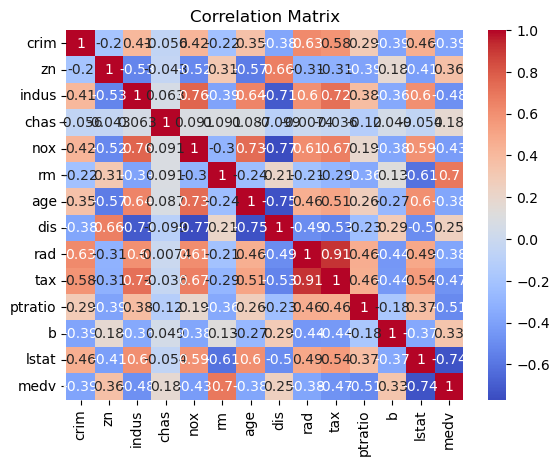

In [ ]:
# Calculate the correlation matrix for numeric columns
corr = df.corr(numeric_only=True)

# Display the correlation matrix sorted by the 'medv' column
print(corr["medv"].sort_values(ascending=False))

# Plot the correlation matrix using a heatmap
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()


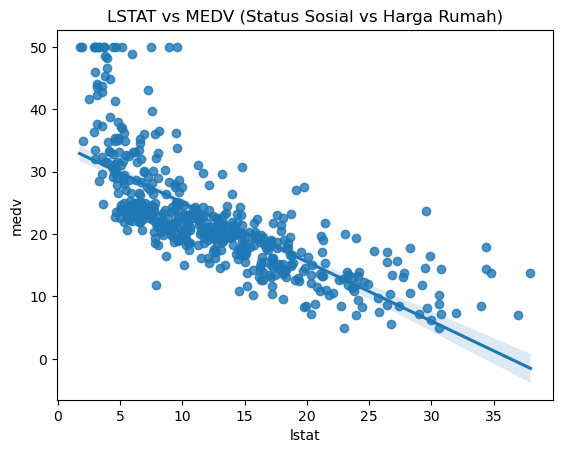

In [ ]:
# Plotting LSTAT vs MEDV (Status Sosial vs Harga Rumah)
sns.regplot(data=df, x='lstat', y='medv')
plt.title("LSTAT vs MEDV (Status Sosial vs Harga Rumah)")
plt.show()

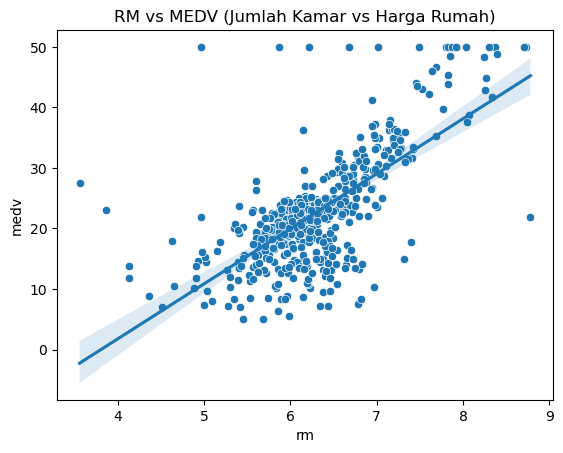

In [ ]:
# Plotting RM vs MEDV (Jumlah Kamar vs Harga Rumah)
sns.scatterplot(data=df, x='rm', y='medv')
sns.regplot(data=df, x='rm', y='medv', scatter=False)
plt.title("RM vs MEDV (Jumlah Kamar vs Harga Rumah)")
plt.show()

In [33]:
df['medv_bin'] = pd.qcut(df['medv'], q=3, labels=['Affordable', 'Mid-range', 'High-end'])

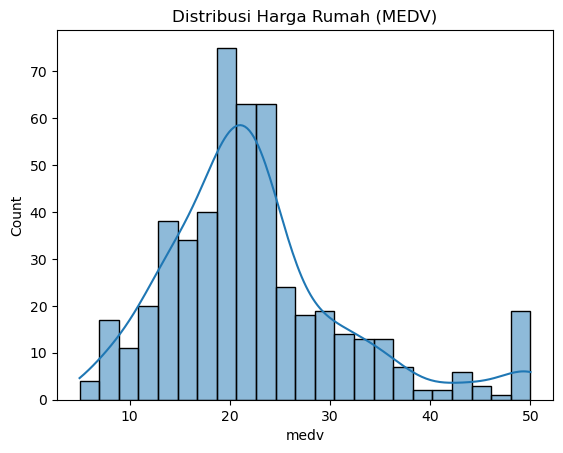

In [36]:
# Plotting the distribution of MEDV (Harga Rumah)
sns.histplot(df['medv'], kde=True)
plt.title("Distribusi Harga Rumah (MEDV)")
plt.show()

🧠 _Interpretasi_: Pasar perumahan di Boston cenderung didominasi oleh rumah dengan harga menengah. Properti dengan harga tinggi adalah segmen khusus, mungkin di lokasi premium atau dengan fitur unggulan.

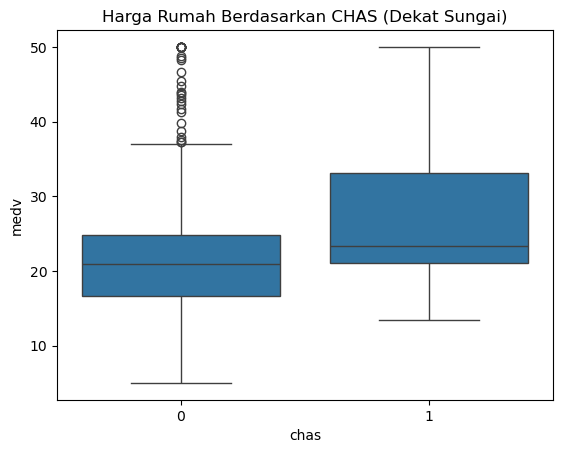

In [ ]:
# Plotting the distribution of CHAS (Dekat Sungai)
sns.boxplot(data=df, x='chas', y='medv')
plt.title("Harga Rumah Berdasarkan CHAS (Dekat Sungai)")
plt.show()

🧠 _Interpretasi_: Lokasi dekat sungai bisa dianggap sebagai faktor premium dalam penentuan harga rumah. Ini bisa jadi karena pemandangan, akses, atau nilai estetika yang lebih tinggi.


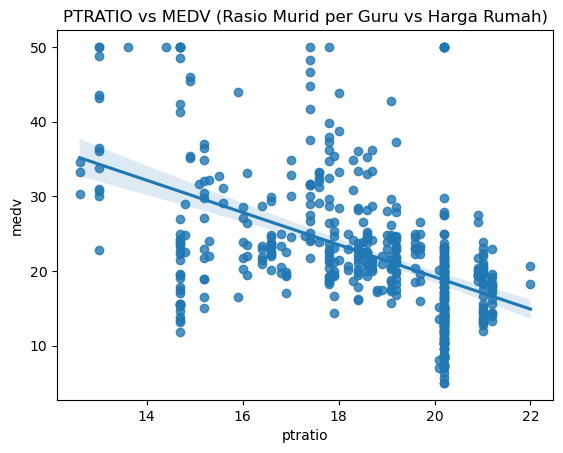

In [31]:
# Plotting the relationship between PTRATIO (Rasio Murid per Guru) and MEDV (Harga Rumah) 
sns.regplot(data=df, x='ptratio', y='medv')
plt.title("PTRATIO vs MEDV (Rasio Murid per Guru vs Harga Rumah)")
plt.show()

🧠 _Interpretasi_: Semakin tinggi rasio murid per guru, harga rumah cenderung lebih rendah. Bisa jadi indikator kualitas pendidikan di area tersebut.

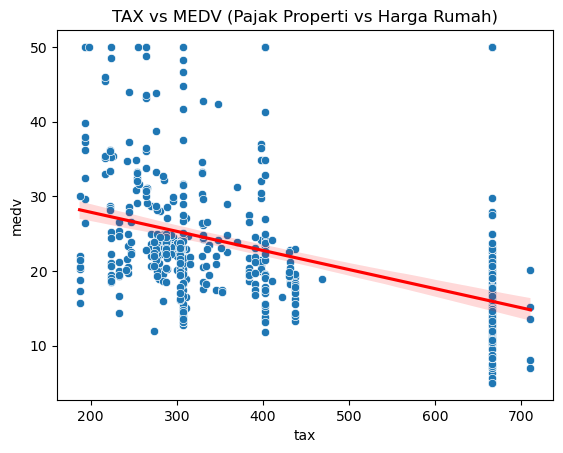

In [ ]:
# Plotting scatter plot and regression line for TAX (Pajak Properti) vs MEDV (Harga Rumah)

sns.scatterplot(data=df, x='tax', y='medv')
sns.regplot(data=df, x='tax', y='medv', scatter=False, color='red')
plt.title("TAX vs MEDV (Pajak Properti vs Harga Rumah)")
plt.show()

🧠 _Interpretasi_: Pajak properti tinggi bisa jadi beban tambahan, sehingga harga rumah cenderung lebih rendah di area dengan pajak tinggi.

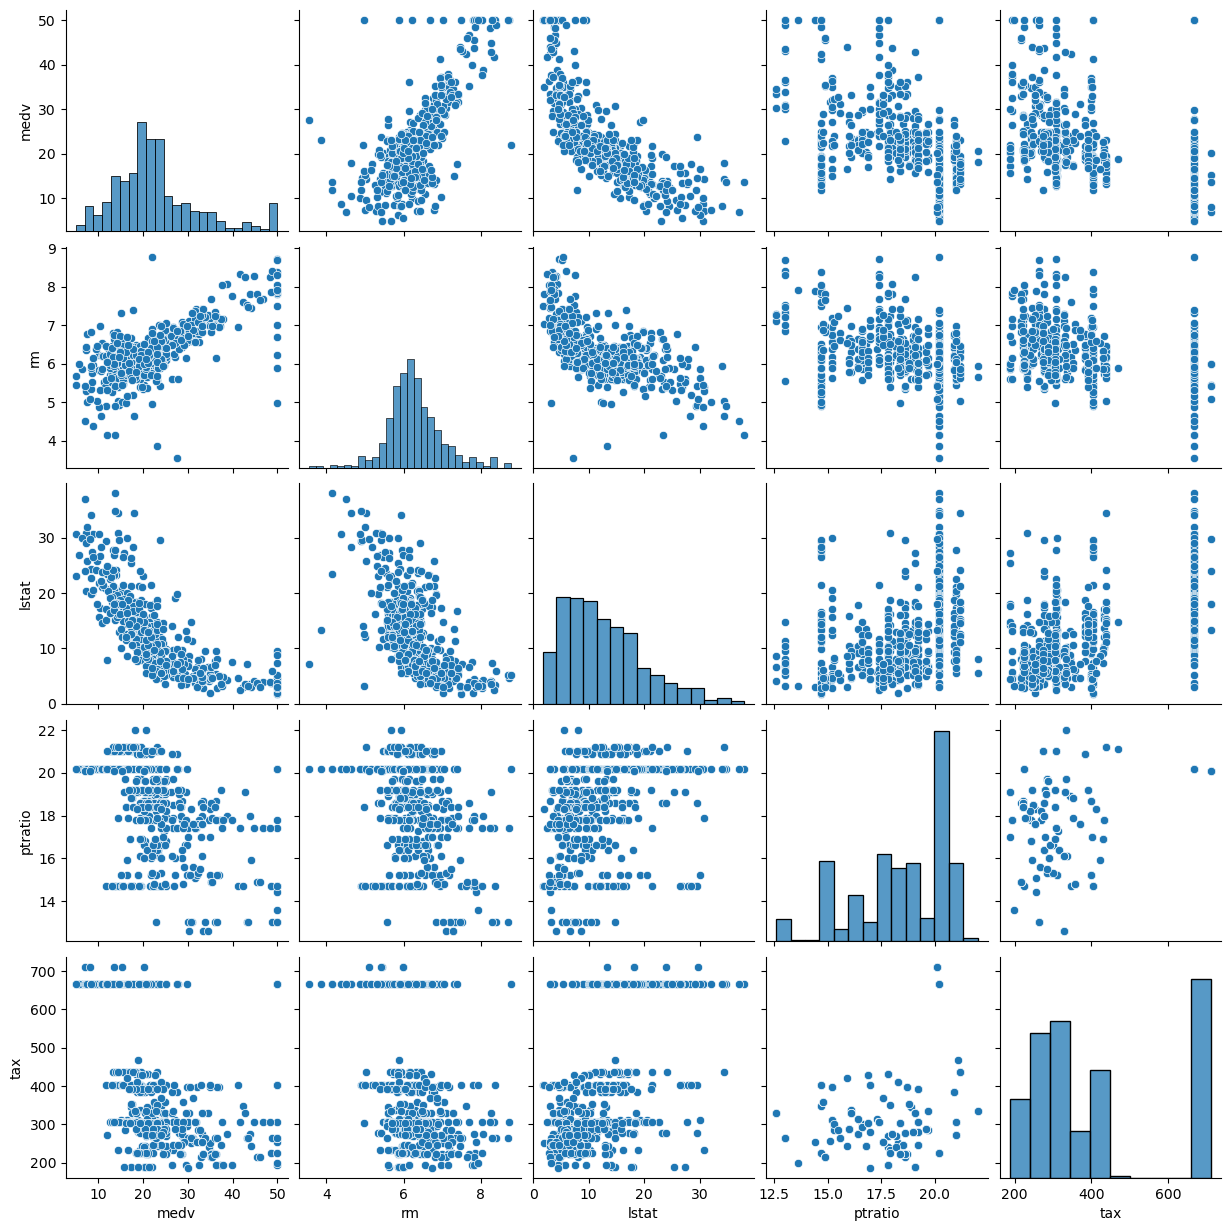

In [30]:
# Plotting the pairplot for selected features
sns.pairplot(df[['medv', 'rm', 'lstat', 'ptratio', 'tax']])
plt.show()

## 🔍 Key Insights

- **Jumlah kamar (RM)** memiliki korelasi positif kuat terhadap harga rumah (MEDV). Rumah dengan lebih banyak kamar cenderung memiliki harga lebih tinggi.
- **LSTAT (status sosial rendah)** menunjukkan korelasi negatif kuat. Area dengan populasi berpenghasilan rendah cenderung memiliki harga rumah lebih murah.
- **PTRATIO (rasio murid per guru)** dan **TAX (pajak properti)** juga menunjukkan korelasi negatif sedang terhadap harga rumah.
- Fitur kategorikal **CHAS** (dekat sungai) menunjukkan sedikit pengaruh positif terhadap harga, meskipun tidak signifikan.

## 🎯 Kesimpulan

Faktor-faktor yang paling berpengaruh terhadap harga rumah di dataset ini adalah:
- **RM** (positif)
- **LSTAT** (negatif)
- **PTRATIO** dan **TAX** (negatif sedang)

Insight ini bisa digunakan untuk membangun model prediksi harga rumah atau sebagai dasar pengambilan keputusan investasi properti.